### Name: Asangika Hettiarachchi ID: 7461502    

# Lab 2 — Spam Classification and Airbnb Outlier Detection

This notebook addresses both parts of Lab 2. Run the cells from top to bottom. Place `Lab2_dataset.csv` and `AB_NYC_2019.csv` in a `data` folder beside this notebook, or update the paths in the loading cells. Results and conclusions are calculated from the data when the notebook runs; they are not hard-coded.


### Part A — Spam Classification

### Step 1: Load and inspect the dataset

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# Find the dataset either in ./data or beside the notebook.
def find_dataset(filename):
    candidates = [Path("data") / filename, Path(".") / filename]
    for path in candidates:
        if path.exists():
            return path
    searched = ", ".join(str(p.resolve()) for p in candidates)
    raise FileNotFoundError(
        f"Could not find {filename}. Place it in a ./data folder beside this notebook "
        f"or in the notebook's current directory. Searched: {searched}"
    )

lab2_path = find_dataset("Lab2_dataset.csv")
df = pd.read_csv(lab2_path)
print(f"Loaded: {lab2_path}")
display(df.head())

Loaded: data\Lab2_dataset.csv


,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\nth...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\n( see a...",0
2,3624,ham,"Subject: neon retreat\nho ho ho , we ' re arou...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\nthis deal is to ...,0


#### Step 2: Inspect the data set

In [2]:
required_columns = {"label", "label_num", "text"}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Lab2 dataset is missing required columns: {sorted(missing_columns)}")

print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nDataset information:")
df.info()
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (5171, 4)

Column names: ['Unnamed: 0', 'label', 'text', 'label_num']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5171 entries, 0 to 5170
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  5171 non-null   int64
 1   label       5171 non-null   str  
 2   text        5171 non-null   str  
 3   label_num   5171 non-null   int64
dtypes: int64(2), str(2)
memory usage: 161.7 KB

Missing values:
Unnamed: 0    0
label         0
text          0
label_num     0
dtype: int64


### Step 3: Explore the target labels

In [3]:
# Show examples and check consistency of text and numeric labels.
display(df[["label", "label_num", "text"]].head(10))
print("Label distribution:")
print(df["label"].value_counts(dropna=False))
print("\nNumeric label distribution:")
print(df["label_num"].value_counts(dropna=False))
print("\nLabel mapping:")
print(pd.crosstab(df["label"], df["label_num"], dropna=False))

# Rows without a message or target cannot be used for supervised training.
rows_before = len(df)
df = df.dropna(subset=["text", "label_num"]).copy()
df["text"] = df["text"].astype(str)
df["label_num"] = pd.to_numeric(df["label_num"], errors="raise").astype(int)
if df["label_num"].nunique() < 2:
    raise ValueError("Classification requires at least two target classes.")
print(f"\nRows removed for missing text/target: {rows_before - len(df)}")

,label,label_num,text
0,ham,0,Subject: enron methanol ; meter # : 988291\nth...
1,ham,0,"Subject: hpl nom for january 9 , 2001\n( see a..."
2,ham,0,"Subject: neon retreat\nho ho ho , we ' re arou..."
3,spam,1,"Subject: photoshop , windows , office . cheap ..."
4,ham,0,Subject: re : indian springs\nthis deal is to ...
5,ham,0,Subject: ehronline web address change\nthis me...
6,ham,0,Subject: spring savings certificate - take 30 ...
7,spam,1,Subject: looking for medication ? we ` re the ...
8,ham,0,Subject: noms / actual flow for 2 / 26\nwe agr...
9,ham,0,"Subject: nominations for oct . 21 - 23 , 2000\..."


Label distribution:
label
ham     3672
spam    1499
Name: count, dtype: int64

Numeric label distribution:
label_num
0    3672
1    1499
Name: count, dtype: int64

Label mapping:
label_num     0     1
label                
ham        3672     0
spam          0  1499

Rows removed for missing text/target: 0


### Step 4: Prepare the Data and Split into Training and Testing Sets

In this step, I select the email text as the input feature and `label_num` as the target variable. I split the dataset into 80% training data and 20% testing data. Stratified sampling preserves the proportion of spam and non-spam messages in both sets.

In [4]:
from sklearn.model_selection import train_test_split

X = df["text"]
y = df["label_num"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Total usable samples:", len(df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTraining label distribution:")
print(y_train.value_counts())
print("\nTesting label distribution:")
print(y_test.value_counts())

Total usable samples: 5171
Training samples: 4136
Testing samples: 1035

Training label distribution:
label_num
0    2937
1    1199
Name: count, dtype: int64

Testing label distribution:
label_num
0    735
1    300
Name: count, dtype: int64


### Step 5: Convert Text into Numerical Features

In this step, I use `CountVectorizer` to transform email messages into numerical word-count features. The vectorizer learns its vocabulary from the training data and applies the same vocabulary to the testing data to prevent data leakage.

In [5]:
from sklearn.feature_extraction.text import CountVectorizer

# Create the CountVectorizer
vectorizer = CountVectorizer(stop_words='english')

# Learn vocabulary and transform training emails
X_train_counts = vectorizer.fit_transform(X_train)

# Transform testing emails using the same vocabulary
X_test_counts = vectorizer.transform(X_test)

# Display the results
print("Training feature matrix shape:", X_train_counts.shape)
print("Testing feature matrix shape:", X_test_counts.shape)

print("\nNumber of unique words:", len(vectorizer.vocabulary_))

# Display a small sample of the numerical features
feature_names = vectorizer.get_feature_names_out()

display(pd.DataFrame(
    X_train_counts[:5, :10].toarray(),
    columns=feature_names[:10]
))

Training feature matrix shape: (4136, 43482)
Testing feature matrix shape: (1035, 43482)

Number of unique words: 43482


,00,000,0000,000000,000000000049773,000080,0001,00018,00020608,0004
0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0
3,2,4,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0


### Step 6: Train Gaussian and Multinomial Naive Bayes Models

In this step, I train two Naive Bayes classifiers using the numerical email features. Multinomial Naive Bayes is suitable for word-count data, while Gaussian Naive Bayes assumes that features follow a Gaussian distribution within each class. I will compare their performance in the next step.

In [6]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB

# Initialize the classifiers
gaussian_model = GaussianNB()
multinomial_model = MultinomialNB()

# Train Gaussian Naive Bayes
# GaussianNB requires a dense array
gaussian_model.fit(X_train_counts.toarray(), y_train)

# Train Multinomial Naive Bayes
# MultinomialNB can use sparse word-count matrices
multinomial_model.fit(X_train_counts, y_train)

print("Gaussian Naive Bayes model trained successfully.")
print("Multinomial Naive Bayes model trained successfully.")

Gaussian Naive Bayes model trained successfully.
Multinomial Naive Bayes model trained successfully.


### Step 7: Evaluate and Compare Model Performance

In this step, I evaluate Gaussian Naive Bayes and Multinomial Naive Bayes using the same test dataset. I compare accuracy, precision, recall, and F1-score, and examine confusion matrices to understand how well each model identifies spam and non-spam emails. The results will help determine which classifier performs better for this dataset.

In [7]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

# Make predictions on the test data
y_pred_gaussian = gaussian_model.predict(X_test_counts.toarray())
y_pred_multinomial = multinomial_model.predict(X_test_counts)

# Compare performance metrics
results = pd.DataFrame({
    "Model": ["Gaussian Naive Bayes", "Multinomial Naive Bayes"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_gaussian),
        accuracy_score(y_test, y_pred_multinomial)
    ],
    "Precision": [
        precision_score(y_test, y_pred_gaussian, zero_division=0),
        precision_score(y_test, y_pred_multinomial, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_gaussian, zero_division=0),
        recall_score(y_test, y_pred_multinomial, zero_division=0)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred_gaussian, zero_division=0),
        f1_score(y_test, y_pred_multinomial, zero_division=0)
    ]
})

display(results.round(4))

# Confusion matrices
print("Gaussian Naive Bayes Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_gaussian))

print("\nMultinomial Naive Bayes Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_multinomial))

,Model,Accuracy,Precision,Recall,F1-Score
0,Gaussian Naive Bayes,0.9546,0.9408,0.9000,0.9199
1,Multinomial Naive Bayes,0.9758,0.9693,0.9467,0.9578


Gaussian Naive Bayes Confusion Matrix:
[[718  17]
 [ 30 270]]

Multinomial Naive Bayes Confusion Matrix:
[[726   9]
 [ 16 284]]


### Results and Interpretation

The next code cell computes the model metrics from the current train/test split. Use those live results rather than copying fixed values from an earlier run. The confusion matrices use the sorted class order shown by `confusion_matrix`; the positive class for precision, recall, and F1 is `label_num = 1` (confirm that this value means spam using the label mapping above).

### Step 8: Predict Email Classes Using Test Data

In this step, I use the trained Multinomial Naive Bayes model to predict whether test emails are spam or ham. I compare the predicted labels with the actual labels to check the model's predictions.

In [8]:
# Select the model with the higher measured F1-score from Step 7.
# If the F1-scores tie, select the model with higher accuracy.
results_sorted = results.sort_values(
    by=["F1-Score", "Accuracy"], ascending=False
)
best_model_name = results_sorted.iloc[0]["Model"]
model_lookup = {
    "Gaussian Naive Bayes": gaussian_model,
    "Multinomial Naive Bayes": multinomial_model,
}
best_model = model_lookup[best_model_name]
print(f"Selected model for test-data predictions: {best_model_name}")

# The first 10 rows of X_test_counts are in the same order as X_test and y_test.
n_samples = min(10, len(X_test))
predicted_labels = best_model.predict(X_test_counts[:n_samples])
actual_labels = y_test.iloc[:n_samples].to_numpy()
email_texts = X_test.iloc[:n_samples].to_numpy()

label_names = {0: "Ham", 1: "Spam"}
prediction_results = pd.DataFrame({
    "Email_Text": email_texts,
    "Actual_Label": [label_names.get(int(v), str(v)) for v in actual_labels],
    "Predicted_Label": [label_names.get(int(v), str(v)) for v in predicted_labels],
})
prediction_results["Correct"] = prediction_results["Actual_Label"] == prediction_results["Predicted_Label"]
display(prediction_results)
print(f"Correct in this sample: {prediction_results['Correct'].sum()} / {n_samples}")

Selected model for test-data predictions: Multinomial Naive Bayes


,Email_Text,Actual_Label,Predicted_Label,Correct
0,Subject: final cp name change and merger repor...,Ham,Ham,True
1,Subject: calpine daily gas nomination\n- hidal...,Ham,Ham,True
2,Subject: calpine daily gas nomination\n>\naime...,Ham,Ham,True
3,"Subject: wells\ndaren , i think i may have los...",Ham,Ham,True
4,Subject: first deliveries - comstock oil & gas...,Ham,Ham,True
5,Subject: 3 . 25 rate confirmation # 367886924 ...,Spam,Spam,True
6,Subject: first delivery - rodessa operating co...,Ham,Ham,True
7,Subject: new pan energy exchange deal meeting\...,Ham,Ham,True
8,Subject: announcement for february 7\nplease t...,Ham,Ham,True
9,Subject: highest gains without guesswork\nwysa...,Spam,Spam,True


Correct in this sample: 10 / 10


### Final Observations and Conclusion

- Compare the live accuracy, precision, recall, and F1-score table from Step 7 to identify the better-performing model.
- Multinomial Naive Bayes is commonly suitable for non-negative word-count features. Gaussian Naive Bayes is included as the required comparison model; its dense-array conversion may use more memory.
- The sample predictions are illustrative only. Evaluate overall model quality using the complete test-set metrics and confusion matrices.
- Confirm the numeric target mapping before interpreting class `1` as spam and class `0` as ham.

### Part B: Airbnb NYC Outlier Detection and Removal

In this part, I use the Airbnb New York City dataset to investigate nightly rental prices and identify potential outliers. I begin by loading the dataset and examining its dimensions, column names, data types, missing values, and price distribution.

In [9]:
airbnb_path = find_dataset("AB_NYC_2019.csv")
df_airbnb = pd.read_csv(airbnb_path)
print(f"Loaded: {airbnb_path}")
if "price" not in df_airbnb.columns:
    raise ValueError("Airbnb dataset must contain a 'price' column.")

# Convert price to numeric, marking malformed values as missing so they can be counted.
df_airbnb["price"] = pd.to_numeric(df_airbnb["price"], errors="coerce")
display(df_airbnb.head())
print("Dataset shape:", df_airbnb.shape)
print("\nColumn names:", df_airbnb.columns.tolist())
print("\nDataset information:")
df_airbnb.info()
print("\nMissing values:")
print(df_airbnb.isnull().sum())

Loaded: data\AB_NYC_2019.csv


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


Dataset shape: (48895, 16)

Column names: ['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                    

### Step 2: Explore Nightly Rental Prices

In this step, I examine the price column using descriptive statistics to understand the typical nightly rental price, variation, and extreme values. This initial analysis helps identify potential outliers before applying statistical techniques.

In [10]:
print("Nightly price statistics:")
print(df_airbnb["price"].describe())
print("\nMissing/unparseable prices:", df_airbnb["price"].isna().sum())
print("Zero-price listings:", (df_airbnb["price"] == 0).sum())
print("Negative-price listings:", (df_airbnb["price"] < 0).sum())

Nightly price statistics:
count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64

Missing/unparseable prices: 0
Zero-price listings: 11
Negative-price listings: 0


### Step 2: Results and Interpretation

Use the descriptive statistics and counts printed above for the actual dataset supplied with your lab. A mean higher than the median often indicates a right-skewed price distribution. Zero and negative prices should be inspected as possible data-quality issues; a statistical outlier is not automatically an invalid listing.

### Step 3: Visualize the original price distribution

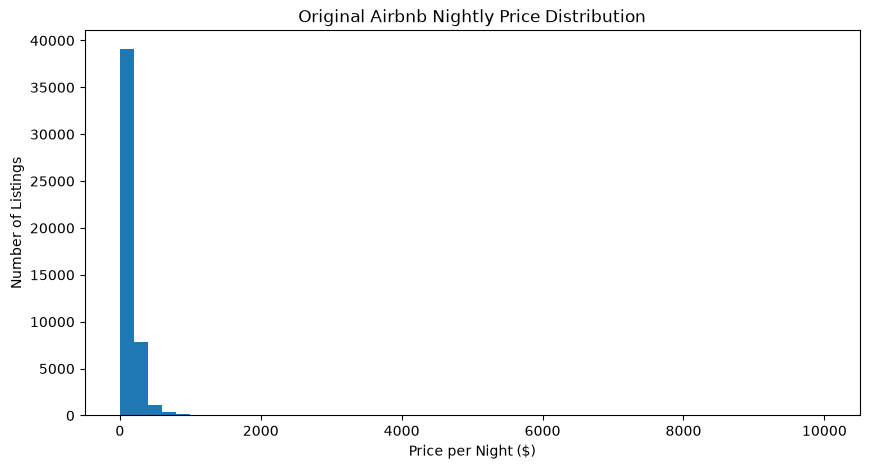

C:\Users\asang\AppData\Local\Temp\ipykernel_19228\2604879949.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df_airbnb["price"].dropna(), vert=False)


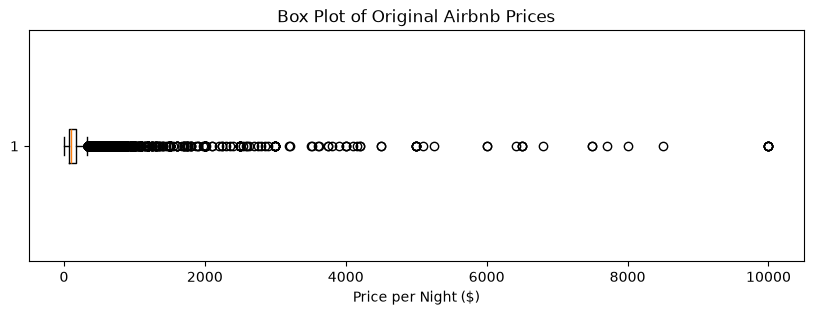

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df_airbnb["price"].dropna(), bins=50)
plt.xlabel("Price per Night ($)")
plt.ylabel("Number of Listings")
plt.title("Original Airbnb Nightly Price Distribution")
plt.show()

# Box plot to highlight potential outliers
plt.figure(figsize=(10, 3))
plt.boxplot(df_airbnb["price"].dropna(), vert=False)
plt.xlabel("Price per Night ($)")
plt.title("Box Plot of Original Airbnb Prices")
plt.show()

### Step 4: Calculate the outlier boundaries

The notebook compares four approaches: mean ± 3 standard deviations, percentile filtering, IQR fences, and a median/MAD method. The median/MAD approach is included because the lab specifically mentions median-based techniques. Each method uses a different definition of an unusual price, so the number of listings removed can differ. These methods flag statistical outliers; they do not prove that a listing is invalid.


In [12]:
# Calculate statistical boundaries using finite, non-missing nightly prices.
prices = df_airbnb.loc[
    df_airbnb["price"].notna() & np.isfinite(df_airbnb["price"]), "price"
]
if prices.empty:
    raise ValueError("No valid numeric nightly prices are available.")

# Method 1: Mean ± 3 standard deviations
mean_price = prices.mean()
std_price = prices.std()
lower_std = mean_price - 3 * std_price
upper_std = mean_price + 3 * std_price

# Method 2: 1st–99th percentiles
lower_percentile = prices.quantile(0.01)
upper_percentile = prices.quantile(0.99)

# Method 3: IQR fences (quartiles and dispersion)
q1 = prices.quantile(0.25)
q3 = prices.quantile(0.75)
iqr = q3 - q1
lower_iqr = q1 - 1.5 * iqr
upper_iqr = q3 + 1.5 * iqr

# Method 4: Median and Median Absolute Deviation (MAD).
# MAD is more robust to extreme values than the mean and standard deviation.
median_price = prices.median()
mad = (prices - median_price).abs().median()
if mad > 0:
    # 3.5 is a commonly used modified-z-score cutoff.
    mad_lower = median_price - (3.5 * 1.4826 * mad)
    mad_upper = median_price + (3.5 * 1.4826 * mad)
else:
    # If MAD is zero, this method cannot provide a useful spread boundary.
    mad_lower, mad_upper = median_price, median_price

print("METHOD 1: Mean ± 3 Standard Deviations")
print(f"Mean: ${mean_price:.2f}; standard deviation: ${std_price:.2f}")
print(f"Lower boundary: ${lower_std:.2f}; upper boundary: ${upper_std:.2f}")

print("\\nMETHOD 2: 1st–99th Percentiles")
print(f"Lower boundary: ${lower_percentile:.2f}; upper boundary: ${upper_percentile:.2f}")

print("\\nMETHOD 3: IQR")
print(f"Q1: ${q1:.2f}; Q3: ${q3:.2f}; IQR: ${iqr:.2f}")
print(f"Lower fence: ${lower_iqr:.2f}; upper fence: ${upper_iqr:.2f}")

print("\\nMETHOD 4: Median and Median Absolute Deviation (MAD)")
print(f"Median: ${median_price:.2f}; MAD: ${mad:.2f}")
print(f"Lower boundary: ${mad_lower:.2f}; upper boundary: ${mad_upper:.2f}")


METHOD 1: Mean ± 3 Standard Deviations
Mean: $152.72; standard deviation: $240.15
Lower boundary: $-567.74; upper boundary: $873.18
\nMETHOD 2: 1st–99th Percentiles
Lower boundary: $30.00; upper boundary: $799.00
\nMETHOD 3: IQR
Q1: $69.00; Q3: $175.00; IQR: $106.00
Lower fence: $-90.00; upper fence: $334.00
\nMETHOD 4: Median and Median Absolute Deviation (MAD)
Median: $106.00; MAD: $46.00
Lower boundary: $-132.70; upper boundary: $344.70


- **Mean ± 3 standard deviations:** identifies prices far from the mean; it can be sensitive to skew and extreme values because both mean and standard deviation are affected by them.
- **Percentiles:** trims a chosen fraction from the lower and upper tails. The 1st–99th percentile method retains the middle 98% by price rank, subject to ties and missing values.
- **IQR:** flags values outside Q1 − 1.5 × IQR and Q3 + 1.5 × IQR. It is more robust to skewed distributions than the mean/standard-deviation rule, but may flag many legitimate high-priced listings.

All boundaries are calculated dynamically from the loaded dataset. For each cleaned version, the code also excludes missing/unparseable and negative prices because these cannot be treated as valid nightly prices.

### Step 5: Compare Outlier-Removal Methods

In this step, I compare the number of Airbnb listings retained and removed by each statistical method. This comparison demonstrates how the choice of outlier-detection technique affects the size and characteristics of the cleaned dataset.

In [13]:
# Keep only finite, non-missing, non-negative nightly prices in each candidate clean dataset.
valid_price = (
    df_airbnb["price"].notna()
    & np.isfinite(df_airbnb["price"])
    & (df_airbnb["price"] >= 0)
)

df_mean_clean = df_airbnb.loc[
    valid_price & df_airbnb["price"].between(max(0, lower_std), upper_std)
].copy()
df_percentile_clean = df_airbnb.loc[
    valid_price & df_airbnb["price"].between(max(0, lower_percentile), upper_percentile)
].copy()
df_iqr_clean = df_airbnb.loc[
    valid_price & df_airbnb["price"].between(max(0, lower_iqr), upper_iqr)
].copy()
df_mad_clean = df_airbnb.loc[
    valid_price & df_airbnb["price"].between(max(0, mad_lower), mad_upper)
].copy()

comparison = pd.DataFrame({
    "Method": [
        "Original Dataset",
        "Mean ± 3 Standard Deviations",
        "1st–99th Percentiles",
        "IQR",
        "Median ± scaled MAD (modified-z-score cutoff 3.5)",
    ],
    "Rows_Remaining": [
        len(df_airbnb),
        len(df_mean_clean),
        len(df_percentile_clean),
        len(df_iqr_clean),
        len(df_mad_clean),
    ],
})
comparison["Rows_Removed"] = len(df_airbnb) - comparison["Rows_Remaining"]
comparison["Percent_Removed"] = (
    comparison["Rows_Removed"] / len(df_airbnb) * 100
).round(2)
display(comparison)
print(
    "Note: removed counts include missing/unparseable and negative prices, "
    "as well as prices outside each method's boundaries."
)


,Method,Rows_Remaining,Rows_Removed,Percent_Removed
0,Original Dataset,48895,0,0.00
1,Mean ± 3 Standard Deviations,48507,388,0.79
2,1st–99th Percentiles,48017,878,1.80
3,IQR,45923,2972,6.08
4,Median ± scaled MAD (modified-z-score cutoff 3.5),45979,2916,5.96


Note: removed counts include missing/unparseable and negative prices, as well as prices outside each method's boundaries.


### Results and Interpretation

Compare the live `comparison` table above. The mean/standard-deviation method, percentile filtering, and IQR filtering will generally retain different numbers of rows because they use different definitions of an outlier. The selected final method below is the 1st–99th percentile method. This is a transparent choice for trimming extreme tails, not proof that all removed listings are erroneous; expensive properties can be legitimate.

### Step 6: Visualize the Cleaned Dataset

In this step, I compare the original nightly price distribution with the distribution after percentile filtering. This helps demonstrate how removing extreme prices changes the distribution and makes the typical nightly prices easier to examine.

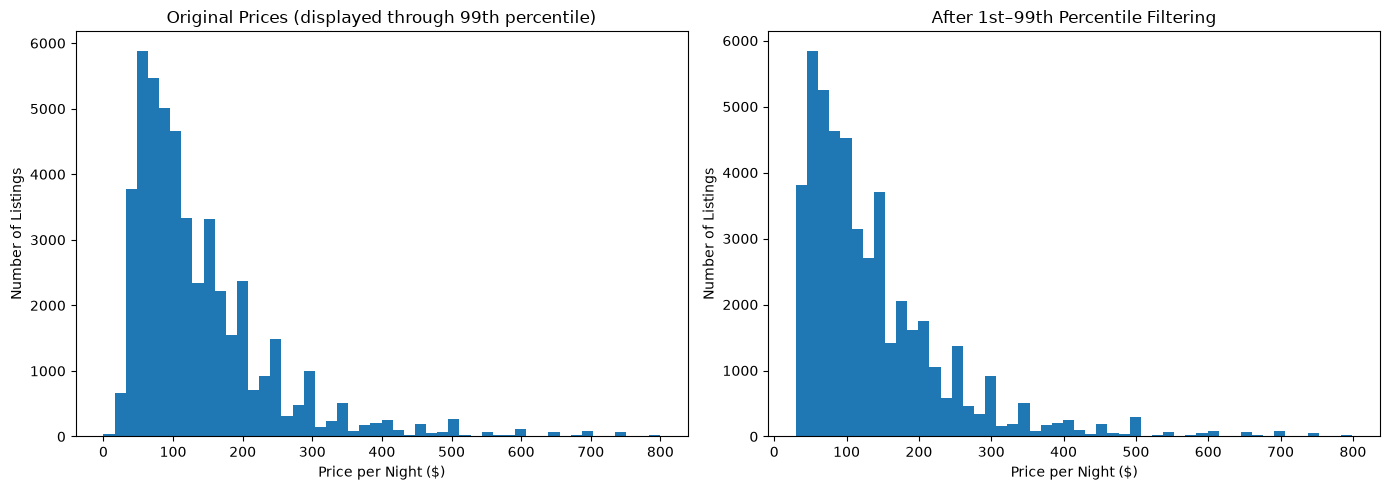

In [14]:
# Compare original and percentile-cleaned price distributions.
original_valid_prices = df_airbnb.loc[
    df_airbnb["price"].notna() & np.isfinite(df_airbnb["price"]) & (df_airbnb["price"] >= 0), "price"
]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(original_valid_prices, bins=50, range=(0, upper_percentile))
axes[0].set_title("Original Prices (displayed through 99th percentile)")
axes[0].set_xlabel("Price per Night ($)")
axes[0].set_ylabel("Number of Listings")
axes[1].hist(df_percentile_clean["price"], bins=50)
axes[1].set_title("After 1st–99th Percentile Filtering")
axes[1].set_xlabel("Price per Night ($)")
axes[1].set_ylabel("Number of Listings")
plt.tight_layout()
plt.show()

### Results and Interpretation

The left histogram displays the original valid, non-negative prices but limits the displayed range to the 99th percentile so the central distribution is visible. The right histogram shows the prices retained by percentile filtering. The distribution may remain right-skewed after cleaning; removing extreme values does not require the data to become normally distributed.

### Step 7: Create the final cleaned dataset

For the final in-notebook dataset, I use the 1st–99th percentile method to remove the most extreme nightly prices. This is a choice for this analysis, not a claim that percentile filtering is always the best method. The comparison table above shows how many rows each method retains, so the choice can be justified using the data.

The code also saves a CSV copy for convenience. **The assignment instructions require submission of the notebook and HTML; they do not explicitly require submitting this CSV separately.**


In [15]:
# Use percentile filtering for the final exported dataset.
df_airbnb_clean = df_percentile_clean.copy()
print("Original dataset shape:", df_airbnb.shape)
print("Cleaned dataset shape:", df_airbnb_clean.shape)
print("\nOriginal price summary:")
display(df_airbnb["price"].describe())
print("\nCleaned price summary:")
display(df_airbnb_clean["price"].describe())

output_path = Path("AB_NYC_2019_Cleaned.csv")
df_airbnb_clean.to_csv(output_path, index=False)
print(f"Cleaned dataset saved to: {output_path.resolve()}")

Original dataset shape: (48895, 16)
Cleaned dataset shape: (48017, 16)

Original price summary:


count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64


Cleaned price summary:


count    48017.000000
mean       138.502010
std        103.694011
min         30.000000
25%         70.000000
50%        105.000000
75%        175.000000
max        799.000000
Name: price, dtype: float64

Cleaned dataset saved to: C:\chandi\chandi\AICourseAtConestoga\Assignments\PROG8000(ArtificialIntelligence)\Lab2\AB_NYC_2019_Cleaned.csv


### Results and Interpretation

The final dataset size, price range, mean, median, and standard deviation are displayed by the previous code cell when you run the notebook. The 1st–99th percentile method is used for the export. Its boundaries are calculated from the actual input file, so report the values generated by your run rather than relying on results from a different copy of the dataset.

## Final Observations and Conclusion

### Part A: Spam Classification

Use the evaluation table and confusion matrices from Part A to identify the stronger model on the test set. The model with the higher test-set metrics is the better performer for this split. Multinomial Naive Bayes is typically well suited to word-count features. Report the metrics actually printed by your notebook, and verify that `label_num = 1` represents spam in the dataset's label mapping.

### Part B: Airbnb Outlier Detection

Three approaches are compared: mean ± 3 standard deviations, 1st–99th percentiles, and the IQR rule. Their row counts and removal percentages are calculated in the comparison table. The notebook selects percentile filtering for the final CSV because it trims the lower and upper tails while retaining most listings.

Outlier treatment depends on the analysis goal. Statistical outliers may be legitimate properties, and zero or malformed prices may be data-quality issues that deserve separate investigation. The exported `AB_NYC_2019_Cleaned.csv` is saved in the notebook's current working directory. Include the dynamically generated statistics from your own run in your final submission.